# Sentiment Analysis of Amazon Product Reviews
### Bidirectional LSTM vs TF-IDF Random Forest

MSc Business & Data Analytics · AI & Machine Learning module (BDA25706) · Ravensbourne University London · 2026

This notebook builds a binary sentiment classifier for Amazon product reviews (positive or negative) and compares a
**Bidirectional LSTM** with a **TF-IDF + Random Forest** baseline. Both models are trained and tested on exactly the
same stratified 80 / 10 / 10 split of a balanced 100,000-review sample, so their scores can be compared directly.

**To run it:** open the notebook in Google Colab and choose **Runtime → Run all**. The dataset is downloaded from
Kaggle while the notebook runs.

## 1. Setup & Imports

In [ ]:
# Install packages that Colab does not include by default
!pip install -q kagglehub wordcloud

In [ ]:
import os
import re
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
warnings.filterwarnings('ignore')

# TensorFlow & Keras
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense,
    Dropout, SpatialDropout1D, GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score, precision_recall_curve, f1_score
)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow version: 2.21.0
GPU available: True


In [ ]:
# ---- Settings (all in one place) ----
SEED = 42                  # used for sampling, splitting and model initialisation
SAMPLE_SIZE = 50000        # reviews per class (100,000 in total)
MAX_VOCAB_SIZE = 25000     # top 25k most frequent words
MAX_SEQUENCE_LENGTH = 150  # pad / truncate every review to 150 tokens
EMBEDDING_DIM = 128        # embedding dimension
BATCH_SIZE = 256
EPOCHS = 10                # upper limit; early stopping usually ends training sooner
RF_TREES = 300             # trees in the Random Forest baseline
FIG_DIR = 'figures'

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.makedirs(FIG_DIR, exist_ok=True)

## 2. Data Collection & Loading

We use the **Amazon Review Polarity** dataset (Zhang, Zhao and LeCun, 2015), as published on Kaggle
(`kritanjalijain/amazon-reviews`). Each review has a title, a body and a label (1 = negative, 2 = positive).
Reviews rated 1–2 stars are labelled negative and 4–5 stars positive; 3-star reviews are not included.

In [ ]:
# Download the dataset from Kaggle
import kagglehub
path = kagglehub.dataset_download("kritanjalijain/amazon-reviews")
print(f"Dataset downloaded to: {path}")

Using Colab cache for faster access to the 'amazon-reviews' dataset.
Dataset downloaded to: /kaggle/input/amazon-reviews


In [ ]:
# List the files in the dataset directory
for root, dirs, files in os.walk(path):
    for f in files:
        filepath = os.path.join(root, f)
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"{filepath} ({size_mb:.1f} MB)")

/kaggle/input/amazon-reviews/amazon_review_polarity_csv.tgz (656.5 MB)
/kaggle/input/amazon-reviews/train.csv (1511.8 MB)
/kaggle/input/amazon-reviews/test.csv (167.9 MB)


In [ ]:
# Load the training file: columns are label, title, review
col_names = ['label', 'title', 'review']
df_train = pd.read_csv(os.path.join(path, 'train.csv'), header=None, names=col_names)

print(f"Reviews in the training file: {df_train.shape[0]:,}")
df_train.head()

Reviews in the training file: 3,600,000


,label,title,review
0,2,Stuning even for the non-gamer,This sound track was beautiful! It paints the ...
1,2,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this ...
2,2,Amazing!,This soundtrack is my favorite music of all ti...
3,2,Excellent Soundtrack,I truly like this soundtrack and I enjoy video...
4,2,"Remember, Pull Your Jaw Off The Floor After He...","If you've played the game, you know how divine..."


In [ ]:
# Draw a balanced sample: SAMPLE_SIZE reviews per class
df_pos = df_train[df_train['label'] == 2].sample(n=SAMPLE_SIZE, random_state=SEED)
df_neg = df_train[df_train['label'] == 1].sample(n=SAMPLE_SIZE, random_state=SEED)
df = pd.concat([df_pos, df_neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
del df_train, df_pos, df_neg  # free memory

# Convert labels: 1 (negative) -> 0, 2 (positive) -> 1
df['sentiment'] = df['label'].map({1: 0, 2: 1})

# Combine title and review for richer text
df['text'] = df['title'].fillna('') + ' ' + df['review'].fillna('')

print(f"Sample shape: {df.shape}")
print("\nClass distribution:")
print(df['sentiment'].value_counts().rename({0: 'Negative', 1: 'Positive'}))

Sample shape: (100000, 5)

Class distribution:
sentiment
Negative    50000
Positive    50000
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)

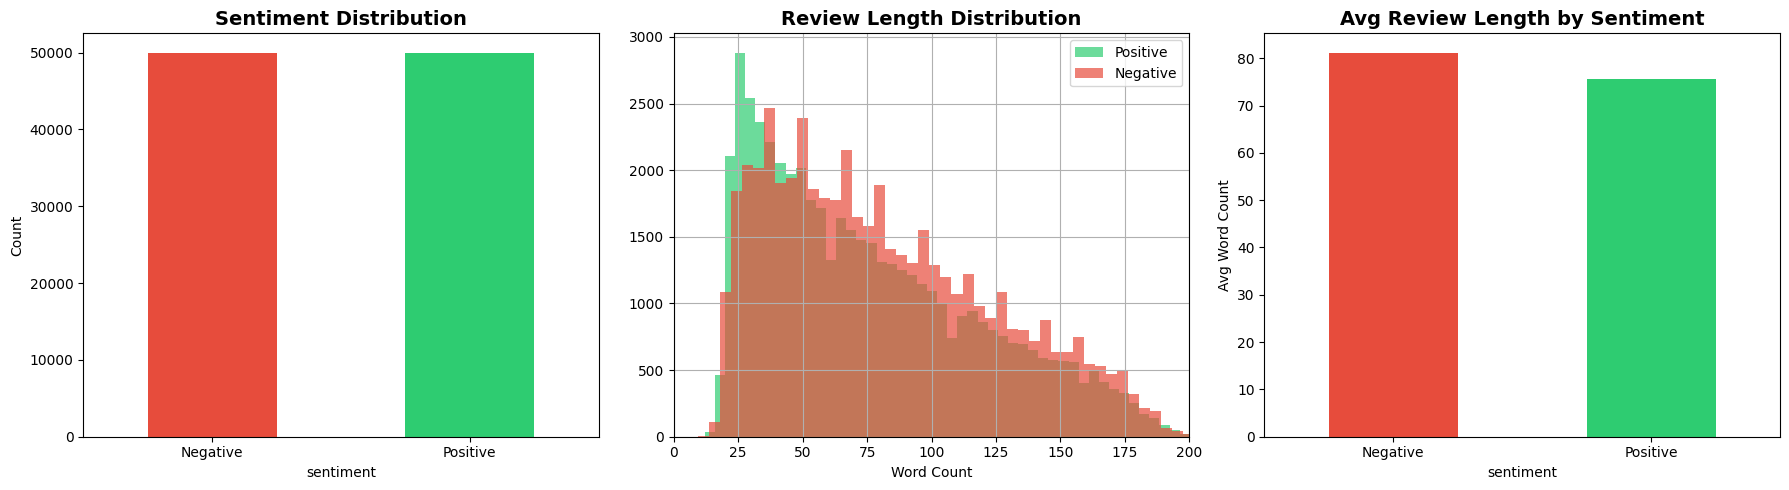


Average review length: 78 words
Median review length: 70 words


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Class distribution
colors = ['#e74c3c', '#2ecc71']
df['sentiment'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color=colors)
axes[0].set_title('Sentiment Distribution', fontsize=14, fontweight='bold')
axes[0].set_xticklabels(['Negative', 'Positive'], rotation=0)
axes[0].set_ylabel('Count')

# Review length distribution
df['review_length'] = df['text'].apply(lambda x: len(x.split()))
df[df['sentiment'] == 1]['review_length'].hist(bins=50, ax=axes[1], alpha=0.7, color='#2ecc71', label='Positive')
df[df['sentiment'] == 0]['review_length'].hist(bins=50, ax=axes[1], alpha=0.7, color='#e74c3c', label='Negative')
axes[1].set_title('Review Length Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].legend()
axes[1].set_xlim(0, 200)

# Average review length by sentiment
avg_lengths = df.groupby('sentiment')['review_length'].mean()
avg_lengths.plot(kind='bar', ax=axes[2], color=colors)
axes[2].set_title('Avg Review Length by Sentiment', fontsize=14, fontweight='bold')
axes[2].set_xticklabels(['Negative', 'Positive'], rotation=0)
axes[2].set_ylabel('Avg Word Count')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nAverage review length: {df['review_length'].mean():.0f} words")
print(f"Median review length: {df['review_length'].median():.0f} words")

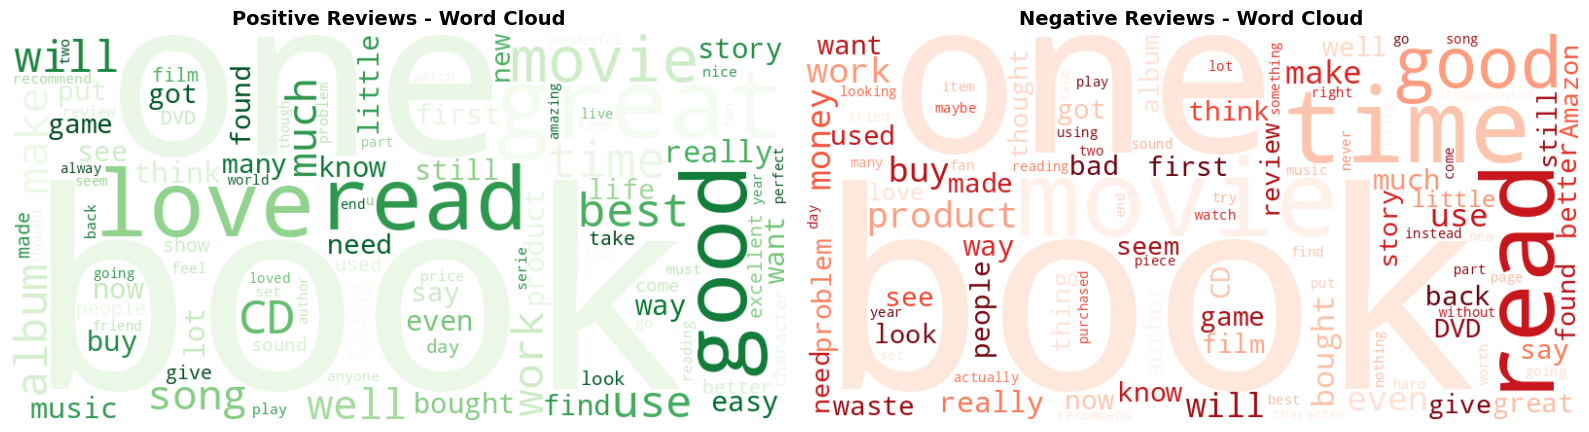

In [ ]:
# Word clouds for positive and negative reviews
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (sentiment, label, cmap) in enumerate([(1, 'Positive', 'Greens'), (0, 'Negative', 'Reds')]):
    text = ' '.join(df[df['sentiment'] == sentiment]['text'].values)
    wc = WordCloud(width=800, height=400, max_words=100, background_color='white',
                   colormap=cmap, random_state=SEED).generate(text)
    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f'{label} Reviews - Word Cloud', fontsize=14, fontweight='bold')
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Data Preprocessing Pipeline

1. **Text cleaning**: remove HTML tags, URLs, email addresses and special characters
2. **Lowercasing**: normalise the text
3. **Train / validation / test split (80 / 10 / 10, stratified)**, done once, before anything is fitted
4. **Tokenization**: the vocabulary is learned from the training split only
5. **Padding**: every review becomes a sequence of exactly 150 tokens

In [ ]:
def clean_text(text):
    """Clean and preprocess text data."""
    if not isinstance(text, str):
        return ''
    text = re.sub(r'<[^>]+>', '', text)          # HTML tags
    text = re.sub(r'http\S+|www\S+', '', text)  # URLs
    text = re.sub(r'\S+@\S+', '', text)         # email addresses
    text = re.sub(r'[^a-zA-Z\s]', '', text)      # special characters and digits
    text = re.sub(r'\s+', ' ', text).strip()     # extra whitespace
    return text.lower()

print("Cleaning text data...")
df['clean_text'] = df['text'].apply(clean_text)

print("\n--- Example ---")
print(f"Original:  {df['text'].iloc[0][:200]}...")
print(f"Cleaned:   {df['clean_text'].iloc[0][:200]}...")

Cleaning text data...

--- Example ---
Original:  East Side Kids: 10 Bowery classics The video quality was very poor. It had very dark images, with poor to fair quality of sound. I would not recommend spending the money on this set! Unless you are a ...
Cleaned:   east side kids bowery classics the video quality was very poor it had very dark images with poor to fair quality of sound i would not recommend spending the money on this set unless you are a big big ...


In [ ]:
# Split ONCE into train / validation / test (80 / 10 / 10, stratified by sentiment).
# We split row positions, so the BiLSTM and the Random Forest use exactly the same reviews
# and every text stays matched to its own label.
y_all = df['sentiment'].values
idx_all = np.arange(len(df))

idx_train, idx_temp = train_test_split(idx_all, test_size=0.2, random_state=SEED, stratify=y_all)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=SEED, stratify=y_all[idx_temp])

texts_train = df['clean_text'].values[idx_train]
texts_val = df['clean_text'].values[idx_val]
texts_test = df['clean_text'].values[idx_test]
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

print(f"Training set:   {len(idx_train):,} reviews")
print(f"Validation set: {len(idx_val):,} reviews")
print(f"Test set:       {len(idx_test):,} reviews")

Training set:   80,000 reviews
Validation set: 10,000 reviews
Test set:       10,000 reviews


In [ ]:
# Tokenization and padding. The vocabulary comes from the training split only,
# so nothing from the validation or test reviews influences the model's inputs.
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(texts_train)

def to_padded(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts),
                         maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

X_train, X_val, X_test = to_padded(texts_train), to_padded(texts_val), to_padded(texts_test)

print(f"Words in the training vocabulary: {len(tokenizer.word_index):,} (top {MAX_VOCAB_SIZE:,} used)")
print(f"Input shape (train): {X_train.shape}")

Words in the training vocabulary: 155,147 (top 25,000 used)
Input shape (train): (80000, 150)


## 5. Model Architecture: Bidirectional LSTM

1. **Embedding layer**: learns dense word representations
2. **SpatialDropout1D**: regularisation for the embeddings
3. **Bidirectional LSTM**: reads each review forwards and backwards
4. **GlobalMaxPooling1D**: keeps the strongest signal from each feature across the sequence
5. **Dense layers with dropout**: final classification (sigmoid output)

In [ ]:
def build_bilstm_model(vocab_size, embedding_dim):
    """Build a Bidirectional LSTM model for sentiment classification."""
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, name='embedding'),
        SpatialDropout1D(0.3),
        Bidirectional(
            LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2),
            name='bi_lstm'
        ),
        GlobalMaxPooling1D(name='global_max_pool'),
        Dense(64, activation='relu', name='dense_1'),
        Dropout(0.3),
        Dense(32, activation='relu', name='dense_2'),
        Dropout(0.2),
        Dense(1, activation='sigmoid', name='output')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_bilstm_model(MAX_VOCAB_SIZE, EMBEDDING_DIM)
model.build(input_shape=(None, MAX_SEQUENCE_LENGTH))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 128)       │     3,200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 150, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bi_lstm (Bidirectional)         │ (None, 150, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pool                 │ (None, 256)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,481,729 (13.28 MB)

 Trainable params: 3,481,729 (13.28 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Model Training

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

print("Starting training...\n")
start = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
lstm_train_time = time.time() - start
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f"\nTraining time: {lstm_train_time / 60:.1f} minutes | best epoch (lowest validation loss): {best_epoch}")

Starting training...

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 263s 807ms/step - accuracy: 0.7912 - loss: 0.4354 - val_accuracy: 0.8877 - val_loss: 0.2828 - learning_rate: 0.0010
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 249s 796ms/step - accuracy: 0.9106 - loss: 0.2332 - val_accuracy: 0.9016 - val_loss: 0.2438 - learning_rate: 0.0010
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 249s 794ms/step - accuracy: 0.9347 - loss: 0.1792 - val_accuracy: 0.9026 - val_loss: 0.2494 - learning_rate: 0.0010
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 770ms/step - accuracy: 0.9437 - loss: 0.1584
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
313/313 ━━━━━━━━━━━━━━━━━━━━ 248s 792ms/step - accuracy: 0.9490 - loss: 0.1450 - val_accuracy: 0.9009 - val_loss: 0.2831 - learning_rate: 0.0010
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 262s 791ms/step - accuracy: 0.9652 - loss: 0.1054 - val_accuracy: 0.8979 - val_loss: 0.3205 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model w

## 7. Performance Evaluation (test set)

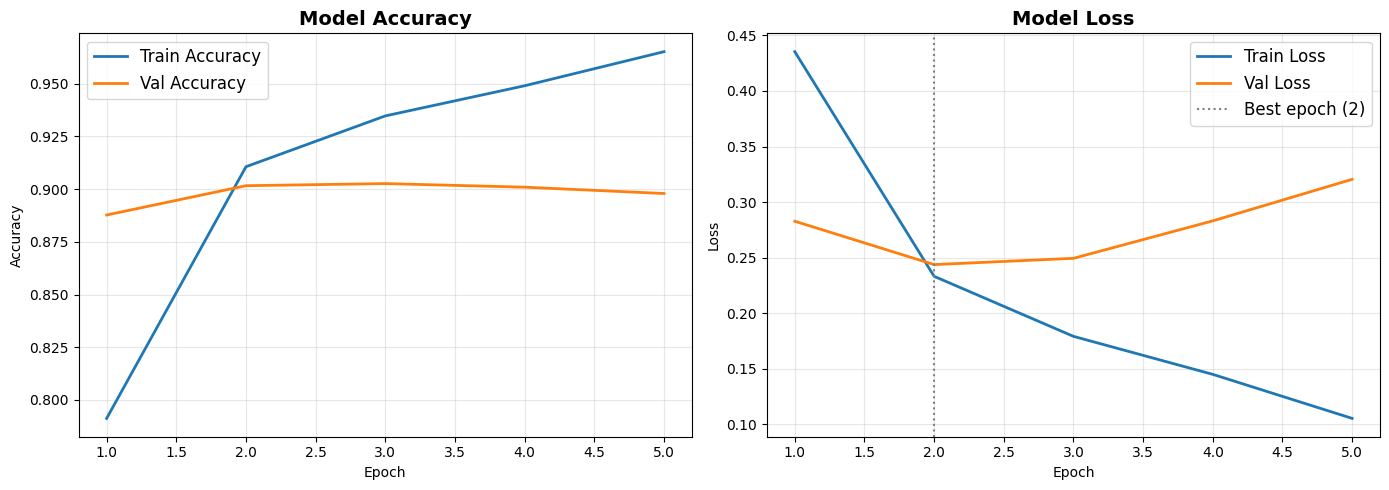

In [ ]:
# Training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(history.history['loss']) + 1)

axes[0].plot(epochs_range, history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[0].plot(epochs_range, history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
axes[0].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history.history['loss'], label='Train Loss', linewidth=2)
axes[1].plot(epochs_range, history.history['val_loss'], label='Val Loss', linewidth=2)
axes[1].axvline(best_epoch, color='grey', linestyle=':', label=f'Best epoch ({best_epoch})')
axes[1].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/training_history.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"{'=' * 50}")
print("TEST SET RESULTS (BiLSTM)")
print(f"{'=' * 50}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Test Loss:     {test_loss:.4f}")
print(f"{'=' * 50}")

TEST SET RESULTS (BiLSTM)
Test Accuracy: 0.8998 (89.98%)
Test Loss:     0.2432


In [ ]:
y_pred_proba = model.predict(X_test, verbose=0).flatten()
y_pred = (y_pred_proba >= 0.5).astype(int)

print("Classification Report (BiLSTM):")
print("=" * 55)
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive'], digits=4))

Classification Report (BiLSTM):
              precision    recall  f1-score   support

    Negative     0.9235    0.8718    0.8969      5000
    Positive     0.8786    0.9278    0.9025      5000

    accuracy                         0.8998     10000
   macro avg     0.9011    0.8998    0.8997     10000
weighted avg     0.9011    0.8998    0.8997     10000



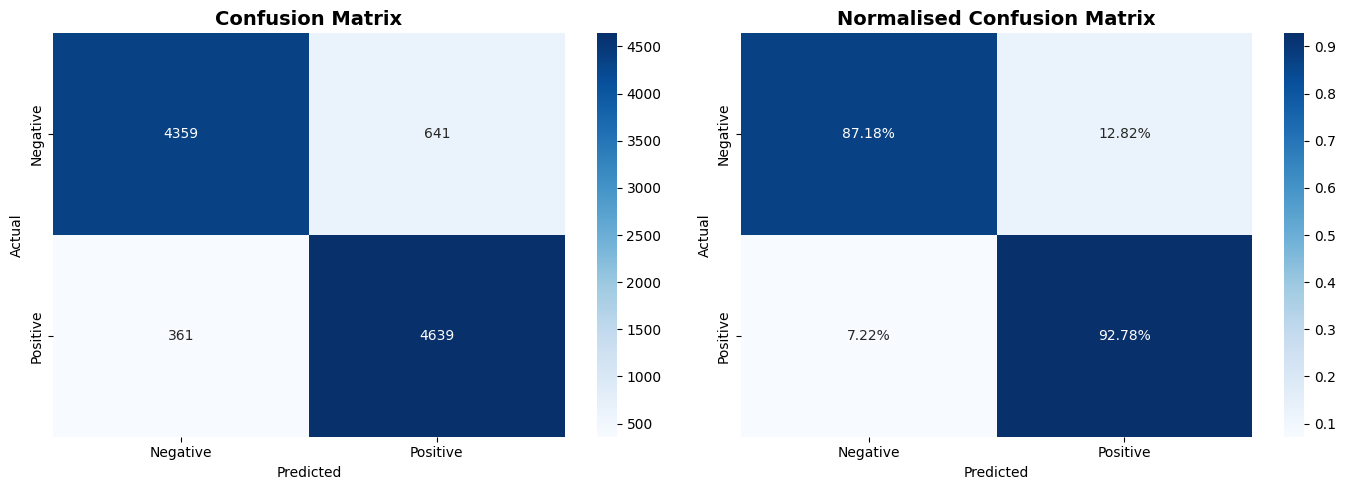

False positives: 641 | False negatives: 361


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[1].set_title('Normalised Confusion Matrix', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"False positives: {fp} | False negatives: {fn}")

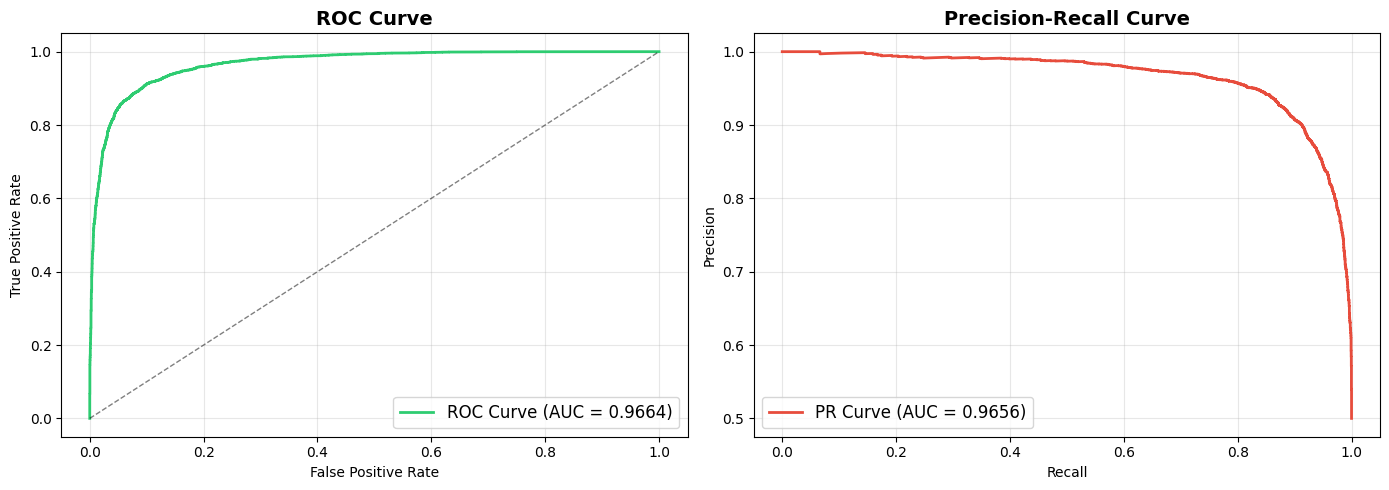

ROC AUC: 0.9664
PR AUC:  0.9656


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color='#2ecc71', linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5)
axes[0].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)

precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall, precision)
axes[1].plot(recall, precision, color='#e74c3c', linewidth=2, label=f'PR Curve (AUC = {pr_auc:.4f})')
axes[1].set_title('Precision-Recall Curve', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC:  {pr_auc:.4f}")

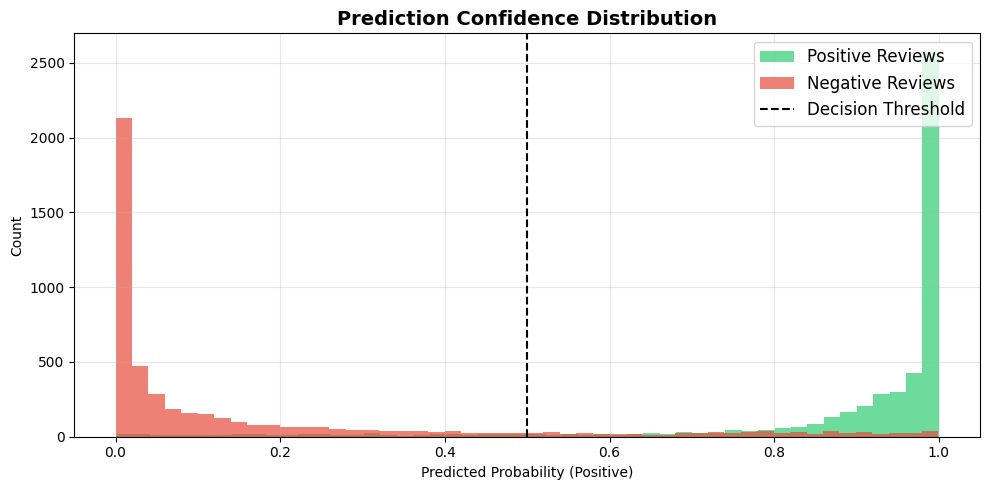

In [ ]:
# Prediction confidence distribution
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, color='#2ecc71', label='Positive Reviews')
ax.hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, color='#e74c3c', label='Negative Reviews')
ax.axvline(x=0.5, color='black', linestyle='--', linewidth=1.5, label='Decision Threshold')
ax.set_title('Prediction Confidence Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Probability (Positive)')
ax.set_ylabel('Count')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confidence_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Error Analysis

In [ ]:
misclassified = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(misclassified):,} of {len(y_test):,} test reviews "
      f"({len(misclassified) / len(y_test):.2%})\n")

def show_errors(positions, heading):
    print(heading)
    print('-' * len(heading))
    for i in positions:
        text = df['text'].iloc[idx_test[i]]
        actual = 'Positive' if y_test[i] == 1 else 'Negative'
        predicted = 'Positive' if y_pred[i] == 1 else 'Negative'
        print(f"Actual: {actual} | Predicted: {predicted} | P(positive) = {y_pred_proba[i]:.3f}")
        print(f"  \"{text[:280]}{'...' if len(text) > 280 else ''}\"\n")

# The most confident mistakes, then a random sample of mistakes
confidence_of_error = np.abs(y_pred_proba[misclassified] - 0.5)
show_errors(misclassified[np.argsort(-confidence_of_error)[:5]], "Most confident mistakes")
rng = np.random.default_rng(SEED)
show_errors(rng.choice(misclassified, size=min(5, len(misclassified)), replace=False), "Random sample of mistakes")

Misclassified: 1,002 of 10,000 test reviews (10.02%)

Most confident mistakes
-----------------------
Actual: Negative | Predicted: Positive | P(positive) = 0.999
  "best priced fountain rhis is an incredible fountain and the price is so low, thanks to amazon, Its very well made to last years, attarcts birds in the yard by the Dozens!!100 percent satisfied"

Actual: Negative | Predicted: Positive | P(positive) = 0.998
  "98% AWESOME...2% makes it 2 stars! I have read every Nelson DeMille book as soon as it has come out ever since picking up Charm School (<-- UNBELIEVABLE book! 7 stars!) Night Fall really grabbed me early, as do most of DeMille's books. However, the end of the book is a complete c..."

Actual: Negative | Predicted: Positive | P(positive) = 0.998
  "My Review I love Mr. Bean! Although this isn't one of his better ones its still funny to see him painstakingly try to make a sandwitch. The 7 others are also great, in order. Amazing Adventures, Exciting Escapades,Terrible Ta

## 9. Baseline Comparison: TF-IDF + Random Forest

The baseline is trained and tested on **exactly the same reviews** as the BiLSTM (the split from section 4).
TF-IDF is fitted on the training texts only.

In [ ]:
print("=" * 60)
print("Training Random Forest with TF-IDF features")
print("=" * 60)

tfidf = TfidfVectorizer(
    max_features=MAX_VOCAB_SIZE,  # same vocabulary size as the LSTM
    ngram_range=(1, 2),           # unigrams + bigrams
    min_df=2,
    max_df=0.95,
    sublinear_tf=True             # log-scaled term frequency
)
X_train_tfidf = tfidf.fit_transform(texts_train)
X_test_tfidf = tfidf.transform(texts_test)
print(f"TF-IDF matrix shape (train): {X_train_tfidf.shape}")

start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=RF_TREES,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    n_jobs=-1,
    random_state=SEED
)
rf_model.fit(X_train_tfidf, y_train)
rf_train_time = time.time() - start

rf_pred = rf_model.predict(X_test_tfidf)
rf_pred_proba = rf_model.predict_proba(X_test_tfidf)[:, 1]
rf_accuracy = (rf_pred == y_test).mean()
rf_roc_auc = roc_auc_score(y_test, rf_pred_proba)
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_pred_proba)
rf_pr_auc = auc(rf_recall, rf_precision)
rf_f1 = f1_score(y_test, rf_pred, average='weighted')

print(f"\nTraining time: {rf_train_time:.1f} seconds")
print(f"Test Accuracy: {rf_accuracy:.4f} ({rf_accuracy * 100:.2f}%)")
print(f"ROC AUC:       {rf_roc_auc:.4f}")
print(f"F1 (weighted): {rf_f1:.4f}")
print("\nClassification Report (Random Forest):")
print(classification_report(y_test, rf_pred, target_names=['Negative', 'Positive'], digits=4))

Training Random Forest with TF-IDF features
TF-IDF matrix shape (train): (80000, 25000)

Training time: 417.5 seconds
Test Accuracy: 0.8677 (86.77%)
ROC AUC:       0.9419
F1 (weighted): 0.8677

Classification Report (Random Forest):
              precision    recall  f1-score   support

    Negative     0.8647    0.8718    0.8682      5000
    Positive     0.8707    0.8636    0.8672      5000

    accuracy                         0.8677     10000
   macro avg     0.8677    0.8677    0.8677     10000
weighted avg     0.8677    0.8677    0.8677     10000



In [ ]:
lstm_f1 = f1_score(y_test, y_pred, average='weighted')
comparison = pd.DataFrame({
    'Random Forest (TF-IDF)': [rf_accuracy, rf_f1, rf_roc_auc, rf_pr_auc],
    'BiLSTM': [test_accuracy, lstm_f1, roc_auc, pr_auc],
}, index=['Accuracy', 'F1 (weighted)', 'ROC AUC', 'PR AUC'])
comparison['Difference (BiLSTM - RF)'] = comparison['BiLSTM'] - comparison['Random Forest (TF-IDF)']
print(f"Model comparison on the same {len(y_test):,} test reviews:\n")
print(comparison.round(4).to_string())

Model comparison on the same 10,000 test reviews:

               Random Forest (TF-IDF)  BiLSTM  Difference (BiLSTM - RF)
Accuracy                       0.8677  0.8998                    0.0321
F1 (weighted)                  0.8677  0.8997                    0.0320
ROC AUC                        0.9419  0.9664                    0.0245
PR AUC                         0.9422  0.9656                    0.0234


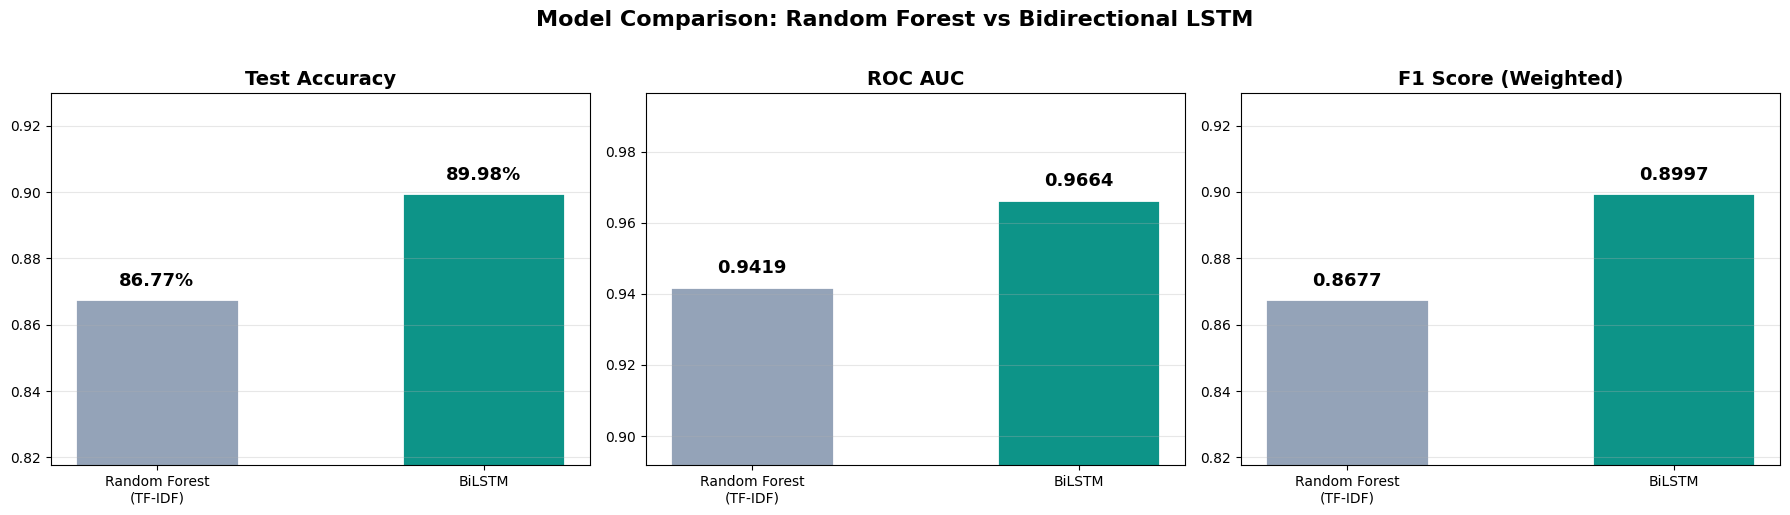

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_names = ['Random Forest\n(TF-IDF)', 'BiLSTM']
colors = ['#94A3B8', '#0D9488']

for ax, (title, values, fmt) in zip(axes, [
        ('Test Accuracy', [rf_accuracy, test_accuracy], '{:.2%}'),
        ('ROC AUC', [rf_roc_auc, roc_auc], '{:.4f}'),
        ('F1 Score (Weighted)', [rf_f1, lstm_f1], '{:.4f}')]):
    bars = ax.bar(model_names, values, color=colors, edgecolor='white', linewidth=2, width=0.5)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_ylim(min(values) - 0.05, min(1.0, max(values) + 0.03))
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004,
                fmt.format(val), ha='center', fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Model Comparison: Random Forest vs Bidirectional LSTM', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

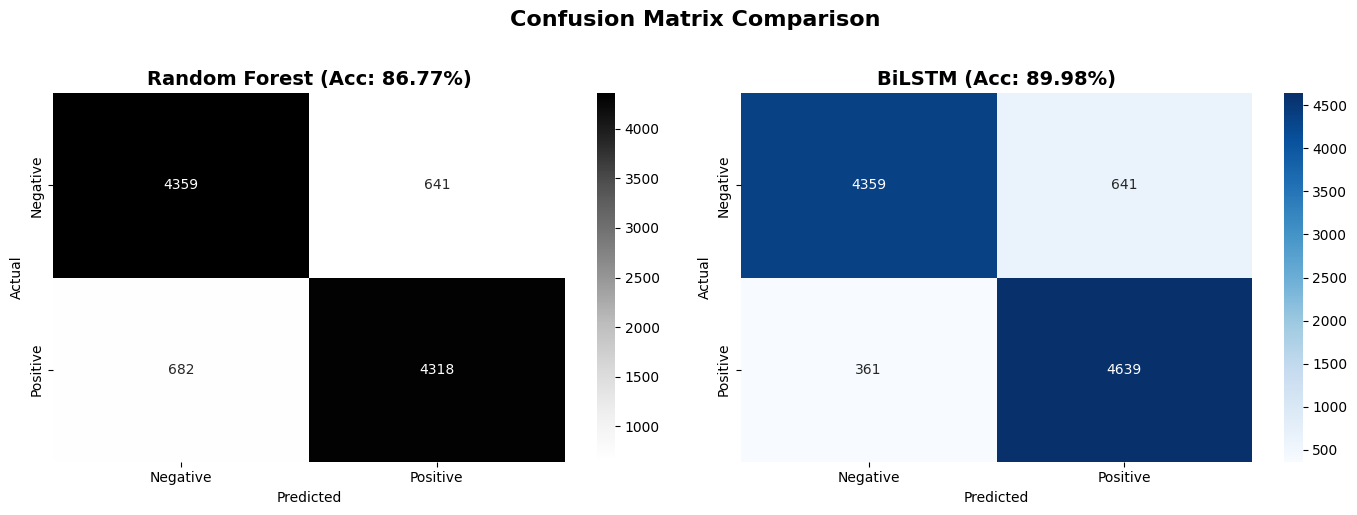

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_rf = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greys', ax=axes[0],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[0].set_title(f'Random Forest (Acc: {rf_accuracy:.2%})', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[1].set_title(f'BiLSTM (Acc: {test_accuracy:.2%})', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.suptitle('Confusion Matrix Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confusion_matrix_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

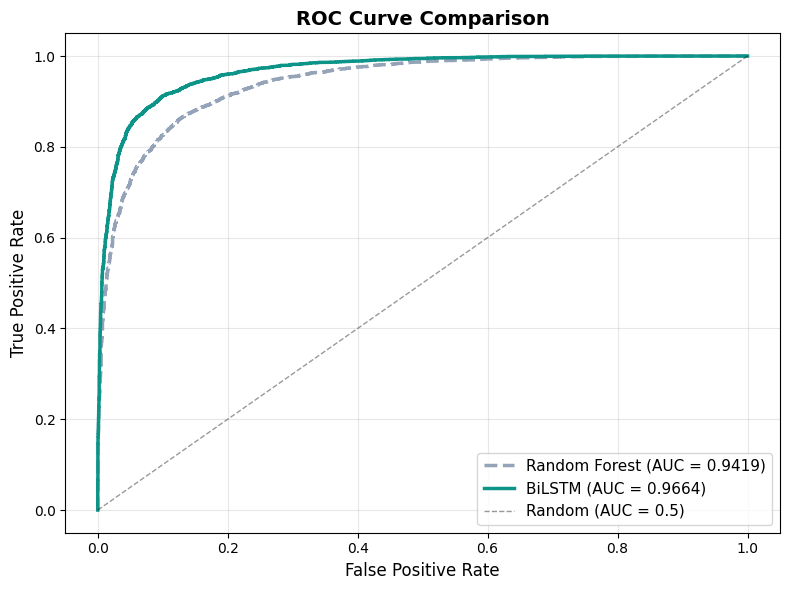

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_pred_proba)
ax.plot(fpr_rf, tpr_rf, color='#94A3B8', linewidth=2.5, linestyle='--',
        label=f'Random Forest (AUC = {rf_roc_auc:.4f})')
ax.plot(fpr, tpr, color='#0D9488', linewidth=2.5, label=f'BiLSTM (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.4, label='Random (AUC = 0.5)')
ax.set_title('ROC Curve Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Live Inference Demo

Predict the sentiment of new, unseen text. The last two examples test negation.

In [ ]:
def predict_sentiment(text, model=model, tokenizer=tokenizer, max_len=MAX_SEQUENCE_LENGTH):
    """Predict the sentiment of a piece of text. Returns the label, confidence and raw score."""
    padded = pad_sequences(tokenizer.texts_to_sequences([clean_text(text)]),
                           maxlen=max_len, padding='post', truncating='post')
    prob = float(model.predict(padded, verbose=0)[0][0])
    sentiment = 'POSITIVE' if prob >= 0.5 else 'NEGATIVE'
    confidence = prob if prob >= 0.5 else 1 - prob
    print(f"{sentiment:<9} ({confidence:.1%})  \"{text}\"")
    return sentiment, confidence, prob

demo_reviews = [
    "This product is absolutely amazing! Best purchase I've ever made. Works perfectly and arrived on time.",
    "Terrible quality. Broke after two days. Complete waste of money. Do not buy this.",
    "It's okay, nothing special. Does what it says but the build quality could be better.",
    "I love this! My kids are obsessed with it. Great value for the price.",
    "The delivery was late, the packaging was damaged, and the product doesn't match the description at all.",
    "Decent product for the price. Not the best out there but gets the job done.",
    "This is not good at all.",
    "Not bad at all, actually really useful.",
]
for review in demo_reviews:
    predict_sentiment(review)

POSITIVE  (99.9%)  "This product is absolutely amazing! Best purchase I've ever made. Works perfectly and arrived on time."
NEGATIVE  (100.0%)  "Terrible quality. Broke after two days. Complete waste of money. Do not buy this."
NEGATIVE  (91.9%)  "It's okay, nothing special. Does what it says but the build quality could be better."
POSITIVE  (99.7%)  "I love this! My kids are obsessed with it. Great value for the price."
NEGATIVE  (84.3%)  "The delivery was late, the packaging was damaged, and the product doesn't match the description at all."
POSITIVE  (78.2%)  "Decent product for the price. Not the best out there but gets the job done."
POSITIVE  (62.5%)  "This is not good at all."
NEGATIVE  (87.0%)  "Not bad at all, actually really useful."


## 11. Saving the Model and Results

In [ ]:
model.save('sentiment_lstm_model.keras')
with open('tokenizer.json', 'w') as f:
    f.write(tokenizer.to_json())

results = {
    'sample_size_total': int(len(df)),
    'split': {'train': int(len(idx_train)), 'validation': int(len(idx_val)), 'test': int(len(idx_test))},
    'settings': {'max_vocab_size': MAX_VOCAB_SIZE, 'max_sequence_length': MAX_SEQUENCE_LENGTH,
                 'embedding_dim': EMBEDDING_DIM, 'batch_size': BATCH_SIZE, 'seed': SEED},
    'bilstm': {'accuracy': float(test_accuracy), 'f1_weighted': float(lstm_f1), 'roc_auc': float(roc_auc),
               'pr_auc': float(pr_auc), 'best_epoch': best_epoch,
               'training_minutes': round(lstm_train_time / 60, 1)},
    'random_forest_tfidf': {'accuracy': float(rf_accuracy), 'f1_weighted': float(rf_f1),
                            'roc_auc': float(rf_roc_auc), 'pr_auc': float(rf_pr_auc),
                            'training_seconds': round(rf_train_time, 1)},
}
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "sample_size_total": 100000,
  "split": {
    "train": 80000,
    "validation": 10000,
    "test": 10000
  },
  "settings": {
    "max_vocab_size": 25000,
    "max_sequence_length": 150,
    "embedding_dim": 128,
    "batch_size": 256,
    "seed": 42
  },
  "bilstm": {
    "accuracy": 0.8998000025749207,
    "f1_weighted": 0.8997213815631454,
    "roc_auc": 0.9663550399999999,
    "pr_auc": 0.9655577243579833,
    "best_epoch": 2,
    "training_minutes": 21.2
  },
  "random_forest_tfidf": {
    "accuracy": 0.8677,
    "f1_weighted": 0.8676977759996145,
    "roc_auc": 0.9418575599999999,
    "pr_auc": 0.9422013130579552,
    "training_seconds": 417.5
  }
}


## Notes on this version

This is a cleaned version of the notebook submitted for the module. Compared with the original:

- The Random Forest baseline now uses the same train / test split as the BiLSTM. In the original, its texts were taken
  in their original row order while the labels came from the shuffled split, so texts and labels did not match.
- The tokenizer's vocabulary is learned from the training split only (it was previously fitted on all 100,000 reviews).
- The error analysis shows the text of misclassified reviews.
- The interactive input demo was replaced by a fixed list of examples so the notebook can run from start to finish.